<a href="https://www.kaggle.com/code/mithhhilesh/customer-churn-prediction-using-pyspark-dataframes?scriptVersionId=357712780" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [3]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, when, count, isnan
from pyspark.sql.types import DoubleType

from pyspark.ml import Pipeline
from pyspark.ml.feature import (
    StringIndexer,
    OneHotEncoder,
    VectorAssembler,
    StandardScaler
)
from pyspark.ml.classification import (
    LogisticRegression,
    DecisionTreeClassifier,
    RandomForestClassifier
)
from pyspark.ml.evaluation import (
    BinaryClassificationEvaluator,
    MulticlassClassificationEvaluator
)
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator

In [4]:
spark = SparkSession.builder \
    .appName("TelecomCustomerChurnPrediction") \
    .getOrCreate()

spark.sparkContext.setLogLevel("WARN")

print("Spark version:", spark.version)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/12 15:43:04 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark version: 4.0.4


In [5]:
df = spark.read.csv(
    "/kaggle/input/datasets/blastchar/telco-customer-churn",
    header=True,
    inferSchema=True
)

print("Total rows:", df.count())
print("Total columns:", len(df.columns))

df.show(5, truncate=False)
df.printSchema()

Total rows: 7043
Total columns: 21
+----------+------+-------------+-------+----------+------+------------+----------------+---------------+--------------+------------+----------------+-----------+-----------+---------------+--------------+----------------+-------------------------+--------------+------------+-----+
|customerID|gender|SeniorCitizen|Partner|Dependents|tenure|PhoneService|MultipleLines   |InternetService|OnlineSecurity|OnlineBackup|DeviceProtection|TechSupport|StreamingTV|StreamingMovies|Contract      |PaperlessBilling|PaymentMethod            |MonthlyCharges|TotalCharges|Churn|
+----------+------+-------------+-------+----------+------+------------+----------------+---------------+--------------+------------+----------------+-----------+-----------+---------------+--------------+----------------+-------------------------+--------------+------------+-----+
|7590-VHVEG|Female|0            |Yes    |No        |1     |No          |No phone service|DSL            |No         

In [6]:
df.select("customerID", "tenure", "MonthlyCharges", "Churn").show(10)

df.groupBy("Churn").count().show()

df.describe(
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
).show()

+----------+------+--------------+-----+
|customerID|tenure|MonthlyCharges|Churn|
+----------+------+--------------+-----+
|7590-VHVEG|     1|         29.85|   No|
|5575-GNVDE|    34|         56.95|   No|
|3668-QPYBK|     2|         53.85|  Yes|
|7795-CFOCW|    45|          42.3|   No|
|9237-HQITU|     2|          70.7|  Yes|
|9305-CDSKC|     8|         99.65|  Yes|
|1452-KIOVK|    22|          89.1|   No|
|6713-OKOMC|    10|         29.75|   No|
|7892-POOKP|    28|         104.8|  Yes|
|6388-TABGU|    62|         56.15|   No|
+----------+------+--------------+-----+
only showing top 10 rows
+-----+-----+
|Churn|count|
+-----+-----+
|   No| 5174|
|  Yes| 1869|
+-----+-----+



+-------+------------------+------------------+------------------+
|summary|            tenure|    MonthlyCharges|      TotalCharges|
+-------+------------------+------------------+------------------+
|  count|              7043|              7043|              7043|
|   mean| 32.37114865824223| 64.76169246059922|2283.3004408418697|
| stddev|24.559481023094442|30.090047097678482| 2266.771361883145|
|    min|                 0|             18.25|                  |
|    max|                72|            118.75|             999.9|
+-------+------------------+------------------+------------------+



In [7]:
from pyspark.sql.functions import col, when, trim

# Clean TotalCharges: Replace empty/blank strings with None, then cast to double safely
df = df.withColumn(
    "TotalCharges",
    when(trim(col("TotalCharges")) == "", None)
    .otherwise(col("TotalCharges"))
    .cast("double")
)

# Remove rows with missing target or unusable numeric values
df = df.filter(
    col("Churn").isNotNull() &
    col("tenure").isNotNull() &
    col("MonthlyCharges").isNotNull() &
    col("TotalCharges").isNotNull()
)

# Remove duplicate records
df = df.dropDuplicates(["customerID"])

print("Rows after cleaning:", df.count())

Rows after cleaning: 7032


In [8]:
target_col = "Churn"

df = df.drop("customerID")

numeric_cols = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

categorical_cols = [
    c for c, dtype in df.dtypes
    if c not in numeric_cols + [target_col]
]

print("Numeric features:", numeric_cols)
print("Categorical features:", categorical_cols)

Numeric features: ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [9]:
train_df, test_df = df.randomSplit(
    [0.8, 0.2],
    seed=42
)

print("Training rows:", train_df.count())
print("Testing rows:", test_df.count())

26/10/12 15:43:21 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


Training rows: 5690
Testing rows: 1342


In [10]:
label_indexer = StringIndexer(
    inputCol="Churn",
    outputCol="label",
    stringOrderType="alphabetAsc"
)

In [11]:
indexer = StringIndexer(
    inputCols=categorical_cols,
    outputCols=[f"{c}_idx" for c in categorical_cols],
    handleInvalid="keep"
)

In [12]:
encoder = OneHotEncoder(
    inputCols=[f"{c}_idx" for c in categorical_cols],
    outputCols=[f"{c}_ohe" for c in categorical_cols],
    handleInvalid="keep"
)

In [13]:
assembler = VectorAssembler(
    inputCols=numeric_cols + [
        f"{c}_ohe" for c in categorical_cols
    ],
    outputCol="features",
    handleInvalid="keep"
)

In [14]:
lr = LogisticRegression(
    featuresCol="features",
    labelCol="label",
    maxIter=100,
    regParam=0.01
)

lr_pipeline = Pipeline(stages=[
    label_indexer,
    indexer,
    encoder,
    assembler,
    lr
])

lr_model = lr_pipeline.fit(train_df)

lr_predictions = lr_model.transform(test_df)

lr_predictions.select(
    "label", "prediction", "probability"
).show(10, truncate=False)

+-----+----------+----------------------------------------+
|label|prediction|probability                             |
+-----+----------+----------------------------------------+
|0.0  |1.0       |[0.49547456343556623,0.5045254365644338]|
|1.0  |1.0       |[0.4775302638003239,0.5224697361996762] |
|0.0  |0.0       |[0.7357926879386134,0.2642073120613866] |
|0.0  |0.0       |[0.6428286417770072,0.35717135822299284]|
|1.0  |0.0       |[0.599179560494019,0.400820439505981]   |
|0.0  |0.0       |[0.6650877768853847,0.3349122231146153] |
|0.0  |0.0       |[0.6057405451822424,0.3942594548177576] |
|1.0  |0.0       |[0.5816115711306932,0.4183884288693068] |
|0.0  |0.0       |[0.5877049945872453,0.41229500541275466]|
|1.0  |0.0       |[0.587110296142289,0.41288970385771095] |
+-----+----------+----------------------------------------+
only showing top 10 rows


In [15]:
dt = DecisionTreeClassifier(
    featuresCol="features",
    labelCol="label",
    maxDepth=5,
    seed=42
)

dt_pipeline = Pipeline(stages=[
    label_indexer,
    indexer,
    encoder,
    assembler,
    dt
])

dt_model = dt_pipeline.fit(train_df)

dt_predictions = dt_model.transform(test_df)

In [16]:
rf = RandomForestClassifier(
    featuresCol="features",
    labelCol="label",
    numTrees=100,
    maxDepth=8,
    seed=42
)

rf_pipeline = Pipeline(stages=[
    label_indexer,
    indexer,
    encoder,
    assembler,
    rf
])

rf_model = rf_pipeline.fit(train_df)

rf_predictions = rf_model.transform(test_df)

26/10/12 15:43:51 WARN DAGScheduler: Broadcasting large task binary with size 1221.6 KiB
26/10/12 15:43:52 WARN DAGScheduler: Broadcasting large task binary with size 2024.6 KiB
26/10/12 15:43:53 WARN DAGScheduler: Broadcasting large task binary with size 3.3 MiB


In [17]:
auc_evaluator = BinaryClassificationEvaluator(
    labelCol="label",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

pr_evaluator = BinaryClassificationEvaluator(
    labelCol="label",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderPR"
)

f1_evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="f1"
)

precision_evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="weightedPrecision"
)

recall_evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="weightedRecall"
)

In [18]:
models = {
    "Logistic Regression": lr_predictions,
    "Decision Tree": dt_predictions,
    "Random Forest": rf_predictions
}

results = []

for name, predictions in models.items():
    results.append((
        name,
        auc_evaluator.evaluate(predictions),
        pr_evaluator.evaluate(predictions),
        f1_evaluator.evaluate(predictions),
        precision_evaluator.evaluate(predictions),
        recall_evaluator.evaluate(predictions)
    ))

results_df = spark.createDataFrame(
    results,
    [
        "Model", "ROC_AUC", "PR_AUC",
        "F1", "Weighted_Precision", "Weighted_Recall"
    ]
)

results_df.orderBy(
    col("ROC_AUC").desc()
).show(truncate=False)

26/10/12 15:44:05 WARN DAGScheduler: Broadcasting large task binary with size 1997.7 KiB
26/10/12 15:44:06 WARN DAGScheduler: Broadcasting large task binary with size 1997.7 KiB
26/10/12 15:44:07 WARN DAGScheduler: Broadcasting large task binary with size 2009.5 KiB
26/10/12 15:44:08 WARN DAGScheduler: Broadcasting large task binary with size 2009.5 KiB
26/10/12 15:44:09 WARN DAGScheduler: Broadcasting large task binary with size 2009.5 KiB


+-------------------+------------------+------------------+------------------+------------------+------------------+
|Model              |ROC_AUC           |PR_AUC            |F1                |Weighted_Precision|Weighted_Recall   |
+-------------------+------------------+------------------+------------------+------------------+------------------+
|Random Forest      |0.8570917856632189|0.648627313306447 |0.7912209405860642|0.7917803464045468|0.8047690014903129|
|Logistic Regression|0.8556778352696728|0.6444061017372528|0.8020660096448367|0.7995090733759972|0.8077496274217586|
|Decision Tree      |0.7509025060045467|0.5107244135047662|0.7809673426356949|0.7779192323183168|0.7906110283159464|
+-------------------+------------------+------------------+------------------+------------------+------------------+



In [19]:
rf_tuning_pipeline = Pipeline(stages=[
    label_indexer,
    indexer,
    encoder,
    assembler,
    RandomForestClassifier(
        featuresCol="features",
        labelCol="label",
        seed=42
    )
])

param_grid = ParamGridBuilder() \
    .addGrid(
        rf_tuning_pipeline.getStages()[-1].numTrees,
        [50, 100]
    ) \
    .addGrid(
        rf_tuning_pipeline.getStages()[-1].maxDepth,
        [5, 8, 12]
    ) \
    .build()

cross_validator = CrossValidator(
    estimator=rf_tuning_pipeline,
    estimatorParamMaps=param_grid,
    evaluator=auc_evaluator,
    numFolds=3,
    parallelism=2,
    seed=42
)

# Use the training dataset for tuning only
tuned_model = cross_validator.fit(train_df)

tuned_predictions = tuned_model.transform(test_df)

print(
    "Tuned ROC-AUC:",
    auc_evaluator.evaluate(tuned_predictions)
)

26/10/12 15:46:11 WARN DAGScheduler: Broadcasting large task binary with size 1121.2 KiB
26/10/12 15:46:27 WARN DAGScheduler: Broadcasting large task binary with size 1704.0 KiB
26/10/12 15:46:48 WARN DAGScheduler: Broadcasting large task binary with size 1124.8 KiB
26/10/12 15:48:10 WARN DAGScheduler: Broadcasting large task binary with size 1121.1 KiB
26/10/12 15:48:28 WARN DAGScheduler: Broadcasting large task binary with size 1703.9 KiB
26/10/12 15:48:54 WARN DAGScheduler: Broadcasting large task binary with size 2.4 MiB
26/10/12 15:49:26 WARN DAGScheduler: Broadcasting large task binary with size 3.4 MiB
26/10/12 15:50:05 WARN DAGScheduler: Broadcasting large task binary with size 4.4 MiB
26/10/12 15:50:40 WARN DAGScheduler: Broadcasting large task binary with size 5.4 MiB
26/10/12 15:51:16 WARN DAGScheduler: Broadcasting large task binary with size 3.4 MiB
26/10/12 15:52:37 WARN DAGScheduler: Broadcasting large task binary with size 1228.4 KiB
26/10/12 15:52:56 WARN DAGScheduler:

Tuned ROC-AUC: 0.8570917856632189


In [20]:
rf_classifier = rf_model.stages[-1]

importances = rf_classifier.featureImportances

print(importances)

(62,[0,1,2,3,4,6,7,9,10,12,13,15,16,18,19,20,22,23,24,26,27,28,30,31,32,34,35,36,38,39,40,42,43,44,46,47,48,50,51,52,54,55,57,58,59,60],[0.1537527337630803,0.05014686138710799,0.09146414113735465,0.00499832441568727,0.004104655585461806,0.005722303853029748,0.004997938836784562,0.00518969948364566,0.0062551936646321905,0.003989485234838015,0.004518852071824715,0.0030435853156624676,0.0024947852562524435,0.004435890639530187,0.004661236744536442,0.002466409378192186,0.05355932363516607,0.019225112127516545,0.008364873523943906,0.07868638499742062,0.01691615607420819,0.005377109150783409,0.022099891489777743,0.007583407794490369,0.0054093578228601525,0.018495709845139385,0.0039966505804603794,0.0052634743692368344,0.06301810322711895,0.018363127336842595,0.006764284131872919,0.005904063548303223,0.005746995491169698,0.007296182389829093,0.004938644470106052,0.0049417834709715395,0.007330096256830197,0.1550999427153536,0.0295920905361856,0.017014632880826996,0.010958482908913414,0.0095855

In [21]:
risk_predictions = rf_model.transform(test_df)

risk_predictions.select(
    "tenure",
    "Contract",
    "MonthlyCharges",
    "label",
    "prediction",
    "probability"
).show(20, truncate=False)

26/10/12 16:30:30 WARN DAGScheduler: Broadcasting large task binary with size 2004.0 KiB


+------+--------------+--------------+-----+----------+----------------------------------------+
|tenure|Contract      |MonthlyCharges|label|prediction|probability                             |
+------+--------------+--------------+-----+----------+----------------------------------------+
|1     |Month-to-month|25.25         |0.0  |1.0       |[0.44495713877652143,0.5550428612234786]|
|1     |Month-to-month|25.1          |1.0  |1.0       |[0.4859133652823618,0.5140866347176383] |
|1     |One year      |25.85         |0.0  |0.0       |[0.6771870173453551,0.32281298265464486]|
|1     |Month-to-month|35.9          |0.0  |0.0       |[0.5336072542392328,0.4663927457607672] |
|1     |Month-to-month|45.15         |1.0  |1.0       |[0.47018866411682864,0.5298113358831713]|
|1     |Month-to-month|44.75         |0.0  |0.0       |[0.5190751784524592,0.4809248215475408] |
|1     |Month-to-month|44.55         |0.0  |1.0       |[0.49089628176281336,0.5091037182371866]|
|1     |Month-to-month|45.3   

In [22]:
rf_model.write().overwrite().save(
    "/content/telecom_churn_pipeline"
)

In [23]:
from pyspark.ml import PipelineModel

loaded_model = PipelineModel.load(
    "/content/telecom_churn_pipeline"
)

new_predictions = loaded_model.transform(test_df)

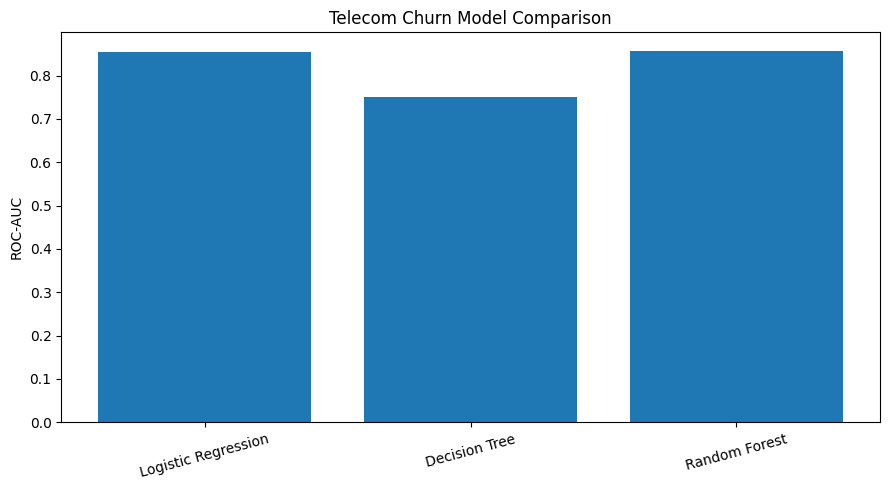

In [24]:
results_pd = results_df.toPandas()

plt.figure(figsize=(9, 5))
plt.bar(results_pd["Model"], results_pd["ROC_AUC"])
plt.ylabel("ROC-AUC")
plt.title("Telecom Churn Model Comparison")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()